<a href="https://colab.research.google.com/github/ThalluriSrinija/24071A67K4_DV_Record/blob/main/week1_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
file_path = '/content/rainfall.csv'
df = pd.read_csv(file_path)
print(df)


        num  altitude  sep  oct  nov  dec  jan  feb  mar  apr  may  \
0    110050        30  1.2   33   90  117  135  102   61   20  6.7   
1    110351        35  2.3   34   86  121  144  106   62   23  4.5   
2    110502        20  2.7   29   89  131  158  109   62   24  3.8   
3    111001        10  2.9   32   91  137  152  113   61   21  4.8   
4    111650        25  1.0   27   78  128  136  108   59   21  4.7   
..      ...       ...  ...  ...  ...  ...  ...  ...  ...  ...  ...   
164  321850      -220  0.2   13   33   53   64   56   35   11  4.7   
165  330370      -375  0.1    6   10   20   22   19   11    6  1.3   
166  337000      -390  0.0    5    3   10    7    7    7    3  0.5   
167  345005        80  0.4    2    2    6    5    4    5    2  0.4   
168  347702        11  0.0    4    2    5    4    3    3    2  1.0   

                  name        x_utm        y_utm  
0    Kfar Rosh Hanikra  696533.0929  3660837.106  
1                 Saar  697119.0761  3656748.194  
2     

In [ ]:
display(df.describe())

,num,altitude,sep,oct,nov,dec,jan,feb,mar,apr,may,x_utm,y_utm
count,1.690000e+02,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,169.000000,1.690000e+02
mean,2.456413e+05,169.911243,1.025444,21.532544,64.852071,105.798817,123.053254,103.130178,58.366864,16.769231,3.968639,699377.463367,3.572778e+06
std,3.102560e+05,258.583316,0.830234,8.226001,24.007849,36.891343,41.072709,35.221167,20.060809,7.111359,2.023557,30980.405658,7.485351e+04
min,1.100500e+05,-390.000000,0.000000,2.000000,2.000000,5.000000,4.000000,3.000000,3.000000,2.000000,0.400000,629301.443000,3.270290e+06
25%,1.382800e+05,30.000000,0.400000,16.000000,51.000000,85.000000,102.000000,89.000000,49.000000,13.000000,2.500000,676015.026400,3.518277e+06
50%,2.139010e+05,95.000000,0.900000,21.000000,68.000000,113.000000,131.000000,106.000000,59.000000,16.000000,4.000000,697119.076100,3.599022e+06
75%,2.474120e+05,255.000000,1.400000,28.000000,82.000000,130.000000,146.000000,123.000000,68.000000,20.000000,5.100000,728581.831500,3.625696e+06
max,2.496029e+06,955.000000,3.700000,40.000000,122.000000,202.000000,238.000000,196.000000,115.000000,40.000000,12.200000,761589.197700,3.681163e+06


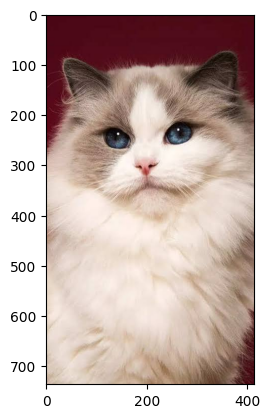

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_path = '/content/cat.jpg'
img = Image.open(image_path)

plt.imshow(img)

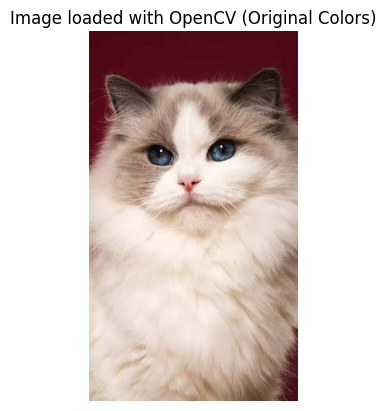

In [ ]:
# using cv2
import cv2
import matplotlib.pyplot as plt

image_path = '/content/cat.jpg'
img = cv2.imread(image_path)

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img_rgb)
plt.axis('off')
plt.title('Image loaded with OpenCV (Original Colors)')
plt.show()

Found 2 eyes:


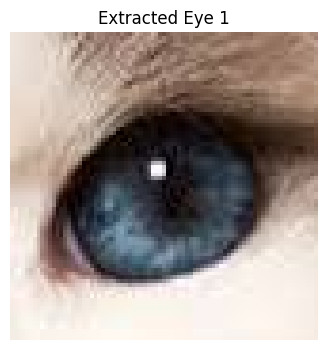

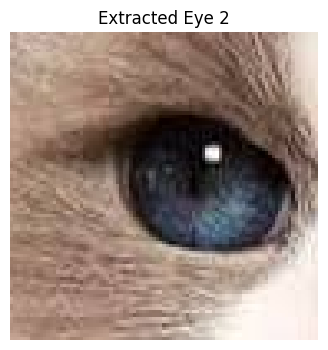

In [ ]:
cat_face_cascade = cv2.CascadeClassifier('haarcascade_frontalcatface.xml')
eye_cascade = cv2.CascadeClassifier('haarcascade_eye.xml')

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

cats = cat_face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

eyes_found = []

for (x, y, w, h) in cats:
    roi_gray = gray[y:y+h, x:x+w]
    roi_color = img_rgb[y:y+h, x:x+w]

    eyes = eye_cascade.detectMultiScale(roi_gray, scaleFactor=1.05, minNeighbors=5, minSize=(10,10))

    for (ex, ey, ew, eh) in eyes:
        eye_img = roi_color[ey:ey+eh, ex:ex+ew]
        eyes_found.append(eye_img)

if eyes_found:
    print(f"Found {len(eyes_found)} eyes:")
    for i, eye in enumerate(eyes_found):
        plt.figure(figsize=(4, 4))
        plt.imshow(eye)
        plt.title(f'Extracted Eye {i+1}')
        plt.axis('off')
        plt.show()
else:
    print("No eyes were detected.")

Found 2 potential ears.


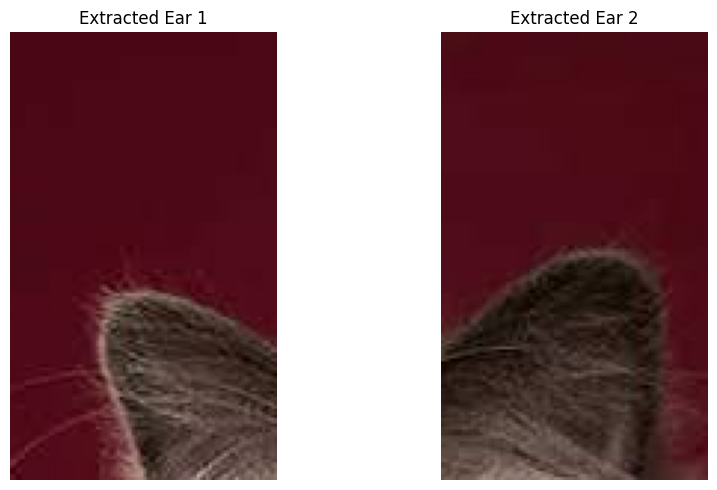

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

if not len(cats):
    print("No cat faces detected, so cannot extract ears.")
else:
    ears_found = []

    for (x, y, w, h) in cats:
        le_x = max(0, x - int(w * 0.15))
        le_y = max(0, y - int(h * 0.4))
        le_w = int(w * 0.3)
        le_h = int(h * 0.5)

        re_x = min(img_rgb.shape[1] - le_w, x + w - int(w * 0.15))
        re_y = max(0, y - int(h * 0.4))
        re_w = int(w * 0.3)
        re_h = int(h * 0.5)

        le_x2 = min(img_rgb.shape[1], le_x + le_w)
        le_y2 = min(img_rgb.shape[0], le_y + le_h)

        re_x2 = min(img_rgb.shape[1], re_x + re_w)
        re_y2 = min(img_rgb.shape[0], re_y + re_h)

        if le_x < le_x2 and le_y < le_y2:
            left_ear_img = img_rgb[le_y:le_y2, le_x:le_x2]
            if left_ear_img.size > 0:
                ears_found.append(left_ear_img)

        if re_x < re_x2 and re_y < re_y2:
            right_ear_img = img_rgb[re_y:re_y2, re_x:re_x2]
            if right_ear_img.size > 0:
                ears_found.append(right_ear_img)

    if ears_found:
        print(f"Found {len(ears_found)} potential ears.")
        plt.figure(figsize=(10, 5))
        for i, ear in enumerate(ears_found):
            # Get dimensions of the current ear image
            h, w, _ = ear.shape
            # Calculate crop coordinates for the central 40% (intermediate zoom)
            crop_h_start = int(h * 0.3)
            crop_h_end = int(h * 0.7)
            crop_w_start = int(w * 0.3)
            crop_w_end = int(w * 0.7)

            # Ensure crop coordinates are valid
            if crop_h_start >= crop_h_end or crop_w_start >= crop_w_end:
                # If the resulting crop area is invalid, display the original ear crop
                cropped_ear = ear
            else:
                # Crop the ear image
                cropped_ear = ear[crop_h_start:crop_h_end, crop_w_start:crop_w_end]

            plt.subplot(1, len(ears_found), i + 1)
            plt.imshow(cropped_ear) # Display the cropped ear
            plt.title(f'Zoomed Ear {i+1}')
            plt.axis('off')
        plt.tight_layout()
        plt.show()
    else:
        print("No ears were detected based on the heuristics.")

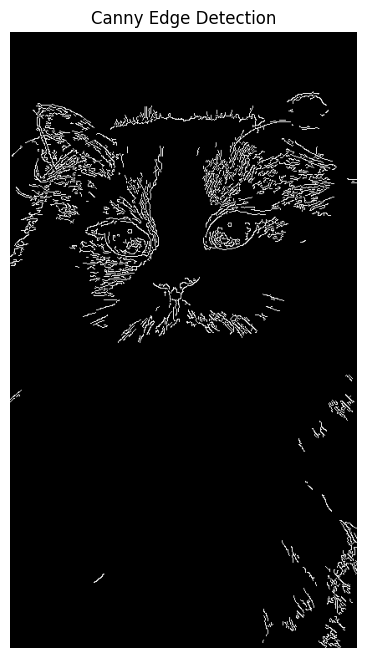

In [22]:
import cv2
import matplotlib.pyplot as plt

# Apply Canny edge detection
edges = cv2.Canny(gray, 100, 200)

plt.figure(figsize=(8, 8))
plt.imshow(edges, cmap='gray')
plt.title('Canny Edge Detection')
plt.axis('off')
plt.show()

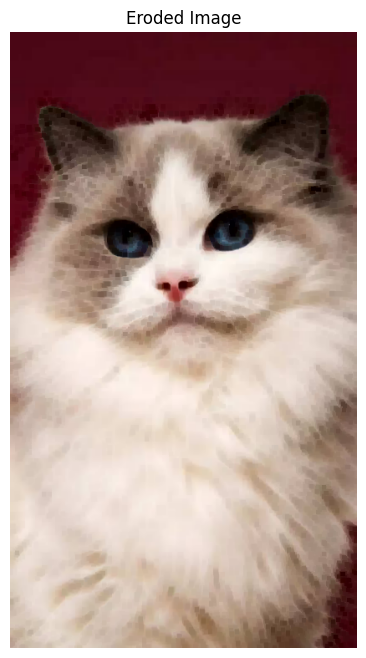

In [23]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Define a kernel for morphological operations
kernel = np.ones((5,5), np.uint8)

# Apply erosion
eroded_image = cv2.erode(img_rgb, kernel, iterations=1)

plt.figure(figsize=(8, 8))
plt.imshow(eroded_image)
plt.title('Eroded Image')
plt.axis('off')
plt.show()

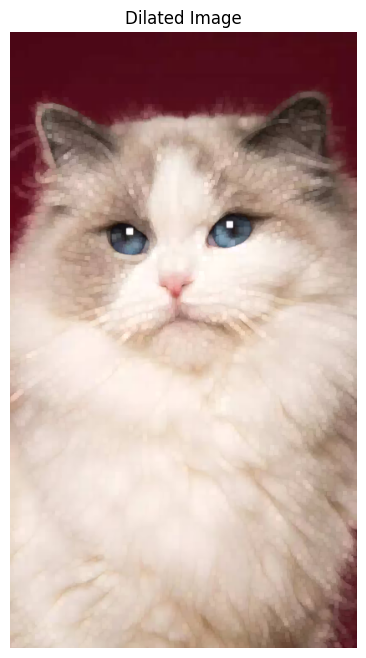

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Define a kernel for morphological operations
kernel = np.ones((5,5), np.uint8)

# Apply dilation
dilated_image = cv2.dilate(img_rgb, kernel, iterations=1)

plt.figure(figsize=(8, 8))
plt.imshow(dilated_image)
plt.title('Dilated Image')
plt.axis('off')
plt.show()